# Implementación CARP para recolección de residuos

## 1. Datos de la instancia


- \(P=2\): número de vehículos.
- \(W=15000\): capacidad de cada vehículo.
- \(n=10\): número de nodos internos.
- \(m=7\): número de arcos que requieren recolectar basura.

Los arcos requeridos son

$$
A_R=\{(1,2),(3,4),(2,5),(5,6),(7,8),(9,10),(10,6)\}.
$$

### Observación importante sobre $(L$)

Con las demandas utilizadas en este cuaderno,

$$
5000,\;5000,\;5000,\;2500,\;2500,\;2000,\;2000,
$$

y $(W=15000)$, la cota construida a partir de la capacidad da

$$
\ell=3,\qquad
L_{\text{cap}}=\left\lceil\frac{7}{3}\right\rceil=3.
$$

Sin embargo, la formulación completa del paper considera (P) viajes iniciales y (P) viajes finales. Con (P=2) se necesitan al menos

$
2P=4
$

índices de viaje. Por ello, **sin cambiar las demandas ni la capacidad**, se usa para la implementación la cota más holgada

$
L=\max\{L_{\text{cap}},2P\}=4.
$



In [31]:
%pip install gurobipy

In [1]:

import math
from itertools import combinations

import gurobipy as gp
from gurobipy import GRB
import networkx as nx
import matplotlib.pyplot as plt



## 1. Definición del grafo

Usaremos:

- \(V\): conjunto de todos los nodos.
- \(U\): nodos internos de la zona de recolección.
- \(A\): conjunto de todos los arcos que pueden recorrerse.
- \(A_R\subseteq A\): arcos que requieren servicio.

Donde,

- `s` representa la **base de la cuadrilla**;
- `t` representa la **instalación de descarga o reciclaje**;
- los nodos `1,...,10` representan intersecciones internas.


In [2]:

# Nodos internos
U = [str(i) for i in range(1,11)]

# Todos los nodos
V = ["s"] + U + ["t"]

# Conjunto de arcos
A = gp.tuplelist([
    ("s","1"), ("1","s"), ("s","3"),
    ("1","2"), ("2","1"),
    ("2","3"),
    ("3","4"), ("4","3"),
    ("4","5"),
    ("2","5"), ("5","2"),
    ("5","6"), ("6","5"),
    ("6","7"), ("7","6"),
    ("7","8"), ("8","7"),
    ("8","9"), ("9","8"),
    ("9","10"), ("10","9"),
    ("10","6"), ("6","10"),
    ("2","t"), ("t","8"),
    ("8","t"), ("9","t"), ("6", "t")
])

# Arcos que requieren recolección
AR = gp.tuplelist([
    ("1","2"),
    ("3","4"),
    ("2","5"),
    ("5","6"),
    ("7","8"),
    ("9","10"),
    ("10","6")
])

print("Nodos internos:", len(U))
print("Arcos totales:", len(A))
print("Arcos requeridos:", len(AR))
print("Arcos no requeridos:", len(A)-len(AR))


Nodos internos: 10
Arcos totales: 28
Arcos requeridos: 7
Arcos no requeridos: 21



## 2. Demandas, capacidad y número de viajes

Sea $(q_{ij})$ la cantidad de residuos recogida en el arco requerido $((i,j))$.

Primero se calcula $(\ell)$ como el mayor número de demandas, ordenadas de mayor a menor, cuya suma no supera la capacidad (W). Luego,

$$
L_{\text{cap}}=
\left\lceil\frac{m}{\ell}\right\rceil.
$$

Como en esta instancia se desea aplicar la estructura completa del paper con \(P=2\), se utilizará

$$
L=\max\{L_{\text{cap}},2P\}.
$$


In [3]:

# Número de vehículos
P = 2

# Capacidad de cada vehículo
W = 15000

# Demandas: se conservan exactamente las del avance
q = {
    ("1","2"): 5000,
    ("3","4"): 5000,
    ("2","5"): 2000,
    ("5","6"): 2500,
    ("7","8"): 2000,
    ("9","10"): 5000,
    ("10","6"): 2500
}

m = len(AR)

# Demandas ordenadas de mayor a menor
demandas = sorted(q.values(), reverse=True)

# Cálculo de ell
acumulado = 0
ell = 0

for demanda in demandas:
    if acumulado + demanda <= W:
        acumulado += demanda
        ell += 1
    else:
        break

# Cota obtenida únicamente a partir de capacidad
L_cap = math.ceil(m/ell)

# Para poder representar P viajes iniciales y P finales
L = max(L_cap, 2*P)

print("Demandas ordenadas:", demandas)
print("ell =", ell)
print("L por capacidad =", L_cap)
print("2P =", 2*P)
print("L usado en el modelo =", L)


Demandas ordenadas: [5000, 5000, 5000, 2500, 2500, 2000, 2000]
ell = 3
L por capacidad = 3
2P = 4
L usado en el modelo = 4



Con \(P=2\) y \(L=4\):

- \(r=1,2\): viajes iniciales, desde `s` hasta `t`;
- \(r=3,4\): viajes finales, desde `t` hasta `s`;
- no existen viajes intermedios en esta instancia.



In [4]:

R = list(range(1,L+1))

R_iniciales = list(range(1,P+1))
R_finales = list(range(P+1,2*P+1))
R_intermedios = list(range(2*P+1,L+1))



In [5]:
# Viajes en los que sí está permitido recoger residuos
# Se excluyen los viajes finales
R_servicio = R_iniciales + R_intermedios

print("Todos los viajes:", R)
print("Viajes iniciales:", R_iniciales)
print("Viajes finales:", R_finales)
print("Viajes intermedios:", R_intermedios)
print("Viajes que pueden prestar servicio:", R_servicio)

Todos los viajes: [1, 2, 3, 4]
Viajes iniciales: [1, 2]
Viajes finales: [3, 4]
Viajes intermedios: []
Viajes que pueden prestar servicio: [1, 2]



También es útil calcular una **cota inferior** sencilla para el número de viajes a partir de la demanda total:

$$
\left\lceil\frac{Q_T}{W}\right\rceil,
\qquad
Q_T=\sum_{(i,j)\in A_R}q_{ij}.
$$

Esta cantidad no es lo mismo que $(L)$:

- $(\lceil Q_T/W\rceil)$ es una cota inferior por capacidad;
- $(L)$ es la cota superior construida con el procedimiento usado en el paper.


In [6]:

QT = sum(q[i,j] for (i,j) in AR)
cota_inferior = math.ceil(QT/W)

print("Demanda total =", QT)
print("Cota inferior por capacidad =", cota_inferior)
print("L usado en el modelo =", L)


Demanda total = 24000
Cota inferior por capacidad = 2
L usado en el modelo = 4


In [7]:
# Verificación de capacidad disponible para los viajes que pueden prestar servicio

capacidad_servicio = len(R_servicio) * W

print("Demanda total:", QT)
print("Número de viajes que pueden recoger:", len(R_servicio))
print("Capacidad total disponible para recolección:", capacidad_servicio)

if QT <= capacidad_servicio:
    print("La instancia puede ser factible desde el punto de vista de capacidad.")
else:
    print("No existe capacidad suficiente para prohibir servicio en los viajes finales.")

Demanda total: 24000
Número de viajes que pueden recoger: 2
Capacidad total disponible para recolección: 30000
La instancia puede ser factible desde el punto de vista de capacidad.



## 3. Gráfico de la instancia

Los arcos requeridos se muestran con mayor grosor. Los demás arcos pueden ser utilizados para desplazamientos sin servicio (*deadheading*).


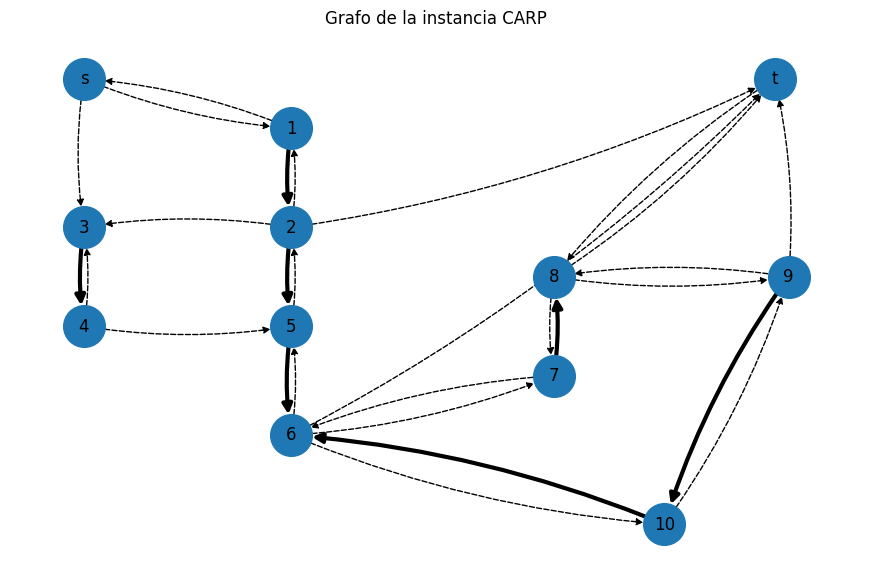

In [8]:
from matplotlib import pyplot

D = nx.DiGraph()
D.add_nodes_from(V)
D.add_edges_from(A)

# Posiciones similares al dibujo original
pos = {
    "s": (0, 5),
    "1": (1.5, 4.5),
    "2": (1.5, 3.5),
    "3": (0, 3.5),
    "4": (0, 2.5),
    "5": (1.5, 2.5),
    "6": (1.5, 1.4),
    "7": (3.4, 2.0),
    "8": (3.4, 3.0),
    "9": (5.1, 3.0),
    "10": (4.2, 0.5),
    "t": (5.0, 5.0)
}

A_no_requeridos = [a for a in A if a not in AR]

plt.figure(figsize=(11, 7))
nx.draw_networkx_nodes(D, pos, node_size=900)
nx.draw_networkx_labels(D, pos)

# Aristas no requeridas (discontinuas)
nx.draw_networkx_edges(
    D, pos,
    edgelist=A_no_requeridos,
    arrows=True,
    node_size=900,   # <-- ¡Añadido para mostrar las flechas!
    arrowsize=10,    # <-- Tamaño de la punta de la flecha
    width=1,
    style="dashed",
    connectionstyle="arc3,rad=0.08"
)

# Aristas requeridas (resaltadas)
nx.draw_networkx_edges(
    D, pos,
    edgelist=AR,
    arrows=True,
    node_size=900,   # <-- ¡Añadido para mostrar las flechas!
    arrowsize=14,    # <-- Tamaño de la punta de la flecha para aristas más gruesas
    width=3,
    connectionstyle="arc3,rad=0.08"
)

plt.title("Grafo de la instancia CARP")
plt.axis("off")
plt.show()



# 4. Formulación del modelo

### Variables principales

Para cada viaje $(r)$:

$$
x_{ij}^r=
\begin{cases}
1,&\text{si el arco requerido }(i,j)\text{ se sirve en el viaje }r,\\
0,&\text{caso contrario.}
\end{cases}
$$

Además,

$$
y_{ij}^r=
\text{número de veces que }(i,j)\text{ se recorre sin prestar servicio}.
$$



## 4.1 Función objetivo

Se consideran:

- $c_{ij}$: costo de recorrer el arco requerido $(i,j)$ prestando servicio;
- $d_{ij}$: costo de recorrer el arco $(i,j)$ sin prestar servicio
  (*deadheading*).

Para los arcos requeridos se considera:

$$
d_{ij}<c_{ij}, \qquad \forall (i,j)\in A_R.
$$

Los valores utilizados son datos simulados en unidades de costo.

La función objetivo es:

$$
\min
\sum_{r\in R}\sum_{(i,j)\in A_R}c_{ij}x_{ij}^r
+
\sum_{r\in R}\sum_{(i,j)\in A}d_{ij}y_{ij}^r.
$$

El primer término representa el costo asociado a prestar el servicio de
recolección y el segundo término representa el costo de los recorridos realizados
sin recoger residuos.

In [9]:
# d[i,j]: costo de recorrer el arco (i,j) sin prestar servicio

d = {
    ("s","1"): 4,
    ("1","s"): 4,
    ("s","3"): 5,

    ("1","2"): 2,
    ("2","1"): 2,
    ("2","3"): 2,

    ("3","4"): 3,
    ("4","3"): 3,
    ("4","5"): 2,

    ("2","5"): 3,
    ("5","2"): 3,

    ("5","6"): 2,
    ("6","5"): 2,

    ("6","7"): 4,
    ("7","6"): 4,

    ("7","8"): 2,
    ("8","7"): 2,

    ("8","9"): 3,
    ("9","8"): 3,

    ("9","10"): 2,
    ("10","9"): 2,

    ("10","6"): 3,
    ("6","10"): 3,

    ("2","t"): 6,
    ("t","8"): 6,

    ("6","t"): 6,
    ("8","t"): 6,
    ("9","t"): 6,
}

# c[i,j]: costo de recorrer un arco requerido prestando servicio.
# Se considera c[i,j] > d[i,j], porque recoger residuos
# genera un costo adicional respecto a solamente circular.

c = {
    ("1","2"): 4,
    ("3","4"): 5,
    ("2","5"): 5,
    ("5","6"): 4,
    ("7","8"): 4,
    ("9","10"): 4,
    ("10","6"): 5
}

print("Viajes potenciales R =", R)

print("\nCostos de servicio:")
for a in AR:
    print(a, "c =", c[a], "  d =", d[a])


Viajes potenciales R = [1, 2, 3, 4]

Costos de servicio:
('1', '2') c = 4   d = 2
('3', '4') c = 5   d = 3
('2', '5') c = 5   d = 3
('5', '6') c = 4   d = 2
('7', '8') c = 4   d = 2
('9', '10') c = 4   d = 2
('10', '6') c = 5   d = 3


In [10]:

# Crear modelo
model = gp.Model("CARP_basico")

# Restricción (15): variables binarias de servicio
# x solo existe para viajes que pueden prestar servicio #####################################################
x = model.addVars(
    [(r,i,j) for r in R_servicio for (i,j) in AR],
    vtype=GRB.BINARY,
    name="x"
)

# Restricción (16): variables enteras no negativas de deadheading
# y existe para todos los viajes##########################################################################################
y = model.addVars(
    [(r,i,j) for r in R for (i,j) in A],
    vtype=GRB.INTEGER,
    lb=0,
    name="y"
)

Restricted license - for non-production use only - expires 2027-11-29



Para simplificar la escritura del código definimos `recorrido(r,i,j)`:

- si $((i,j)\in A_R)$, el arco puede recorrerse por servicio o por deadheading, de modo que aparece$\(x_{ij}^r+y_{ij}^r)$;
- si $((i,j)\notin A_R)$, solamente aparece $(y_{ij}^r)$.

Esta función es únicamente una abreviación de código; no introduce nuevas variables.


In [11]:
def recorrido(r,i,j):
    # Viajes finales: no hay variables x, solo deadheading
    if r in R_finales:
        return y[r,i,j]
    # Viajes de servicio: si el arco es requerido, servicio + deadheading
    if (i,j) in AR:
        return x[r,i,j] + y[r,i,j]
    return y[r,i,j]

In [12]:

#  función objetivo
#3. Función objetivo (la suma de c·x va solo sobre R_servicio)################################################################################################
model.setObjective(
    gp.quicksum(c[i,j]*x[r,i,j] for r in R_servicio for (i,j) in AR)
    +
    gp.quicksum(d[i,j]*y[r,i,j] for r in R for (i,j) in A),
    GRB.MINIMIZE
)



## 5. Restricciones (2)–(16)

Se implementan las restricciones en el mismo orden conceptual del paper:

- (2): continuidad en nodos internos;
- (3)–(5): viajes iniciales;
- (6)–(8): viajes finales;
- **(RF): los viajes finales no pueden prestar servicio de recolección;**
- (9)–(11): viajes intermedios;
- (12): conectividad;
- (13): capacidad;
- (14): servicio exactamente una vez;
- (15)–(16): dominio de las variables.



Para escribir las restricciones de flujo de manera clara, definimos una pequeña función.

Si un arco es requerido, el número total de veces que se recorre durante el viaje es

$$
x_{ij}^r+y_{ij}^r.
$$

Si no es requerido, solamente aparece $(y_{ij}^r)$.


In [13]:

# ---------------------------------------------------------
# (2) CONTINUIDAD EN LOS NODOS INTERNOS
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if j == v
        )
        -
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == v
        )
        == 0
        for v in U
        for r in R
    ),
    name="R2_continuidad"
)


# ---------------------------------------------------------
# (3) VIAJES INICIALES: balance en s
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == "s"
        )
        -
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if j == "s"
        )
        == 1
        for r in R_iniciales
    ),
    name="R3"
)


# ---------------------------------------------------------
# (4) VIAJES INICIALES: llegan una vez a t
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if j == "t"
        )
        == 1
        for r in R_iniciales
    ),
    name="R4"
)


# ---------------------------------------------------------
# (5) VIAJES INICIALES: no salen de t
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if i == "t"
        )
        == 0
        for r in R_iniciales
    ),
    name="R5"
)


# ---------------------------------------------------------
# (6) VIAJES FINALES: balance en s
# ---------------------------------------------------------
model.addConstrs(
    (
        -gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == "s"
        )
        +
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if j == "s"
        )
        == 1
        for r in R_finales
    ),
    name="R6"
)


# ---------------------------------------------------------
# (7) VIAJES FINALES: salen una vez de t
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if i == "t"
        )
        == 1
        for r in R_finales
    ),
    name="R7"
)


# ---------------------------------------------------------
# (8) VIAJES FINALES: no vuelven a entrar a t
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if j == "t"
        )
        == 0
        for r in R_finales
    ),
    name="R8"
)


# ---------------------------------------------------------
# (9) BALANCE EN s PARA VIAJES INTERMEDIOS
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == "s"
        )
        -
        gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if j == "s"
        )
        == 0
        for r in R_intermedios
    ),
    name="R9"
)


# ---------------------------------------------------------
# (10) BALANCE EN t PARA VIAJES INTERMEDIOS
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if i == "t"
        )
        -
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if j == "t"
        )
        == 0
        for r in R_intermedios
    ),
    name="R10"
)


# ---------------------------------------------------------
# (11) COMO MÁXIMO UNA SALIDA DE t EN UN VIAJE INTERMEDIO
# ---------------------------------------------------------
model.addConstrs(
    (
        gp.quicksum(
            y[r,i,j]
            for (i,j) in A
            if i == "t"
        )
        <= 1
        for r in R_intermedios
    ),
    name="R11"
)


{}

### Restricción adicional: prohibición de recolección en los viajes finales

Se desea imponer una condición operativa adicional:
**los viajes finales no pueden recoger residuos**.

Recordemos que

$$
x_{ij}^r =
\begin{cases}
1, & \text{si el arco requerido }(i,j)\text{ es servido durante el viaje }r,\\
0, & \text{caso contrario.}
\end{cases}
$$

Los viajes finales están definidos por

$$
R_F=\{P+1,\ldots,2P\}.
$$

Por tanto, prohibir la recolección durante estos viajes equivale a imponer

$$
x_{ij}^r=0,
\qquad
\forall (i,j)\in A_R,\quad r\in R_F.
$$

De manera equivalente, como las variables $x_{ij}^r$ son binarias y no
negativas, para cada viaje final puede utilizarse la restricción agregada

$$
\sum_{(i,j)\in A_R}x_{ij}^r=0,
\qquad r\in R_F.
$$

Esto no impide que el vehículo recorra calles durante el viaje final.
El desplazamiento desde la instalación de descarga hasta la base continúa
representándose mediante las variables $y_{ij}^r$ de *deadheading*.

Borra la celda de (RF). Ya no se necesita y daría KeyError, porque x[r,i,j] no existe para r final.


In [45]:
# ---------------------------------------------------------
# (RF) VIAJES FINALES SIN RECOLECCIÓN
# ---------------------------------------------------------
# Durante los viajes finales no se permite prestar
# servicio en ningún arco requerido.

#model.addConstrs(
 #   (
  #      gp.quicksum(
   #         x[r,i,j]
    #        for (i,j) in AR
     #   )
      #  == 0
       # for r in R_finales
    #),
    #name="RF_no_servicio_final"
#)

### Formulación compacta para la restricción de conectividad

La formulación anterior aunque permite representar correctamente la conectividad, el número de restricciones crece exponencialmente con el número de nodos,ya que el número de subconjuntos posibles es del orden de $2^{|V|}$.

Para evitar la enumeración de todos estos subconjuntos, se sustituye la
restricción (12) por una formulación compacta basada en un flujo auxiliar
de una mercancía (*Single Commodity Flow*).

La idea consiste en considerar que el nodo $t$, correspondiente a la
instalación de descarga, envía una unidad de flujo ficticio a cada nodo
utilizado durante un viaje.

Este flujo no representa residuos ni vehículos. Su única función es
garantizar conectividad.

Se introduce la variable binaria

$$
z_i^r =
\begin{cases}
1, & \text{si el nodo }i\text{ es utilizado durante el viaje }r,\\
0, & \text{caso contrario},
\end{cases}
$$

y variables continuas no negativas

$$
f_{ij}^r\geq 0,
$$

que representan el flujo auxiliar enviado entre nodos.

El flujo auxiliar solamente puede utilizar conexiones que formen parte
del recorrido del vehículo. De esta manera, si apareciera una componente
aislada, sus nodos deberían recibir flujo, pero dicho flujo no podría
llegar desde $t$, haciendo imposible esa solución. Para el flujo auxiliar se considera la conexión subyacente entre dos nodos,
independientemente de la dirección en que el vehículo la recorre.

Esto es necesario porque la restricción (12) original considera tanto los
arcos que entran a un subconjunto $S$ como los que salen de él. El flujo
auxiliar se utiliza únicamente para comprobar que existe conexión con $t$,
no para representar el sentido real de circulación del vehículo.

In [14]:
# ---------------------------------------------------------
# FORMULACIÓN COMPACTA DE CONECTIVIDAD
# Reemplaza la restricción (12)
# ---------------------------------------------------------

# Construimos el conjunto de conexiones no dirigidas
# que existen en el grafo.

E = []

for (i,j) in A:

    # Para evitar repetir la misma conexión:
    # (i,j) y (j,i) representan la misma conexión auxiliar.
    e = tuple(sorted([i,j]))

    if e not in E:
        E.append(e)

print("Número de conexiones auxiliares:", len(E))

# Para el flujo auxiliar permitimos ambos sentidos
# de cada conexión.

A_flujo = []

for (i,j) in E:

    A_flujo.append((i,j))
    A_flujo.append((j,i))

print("Arcos del flujo auxiliar:", len(A_flujo))



Número de conexiones auxiliares: 17
Arcos del flujo auxiliar: 34


In [15]:
V_sin_t = [v for v in V if v != "t"]
# ---------------------------------------------------------
# Variables auxiliares para conectividad compacta
# ---------------------------------------------------------

# z[r,v] = 1 si el nodo v es utilizado en el viaje r
# No necesitamos definir z para t, ya que t es la raíz
# de la conectividad.

z = model.addVars(
    [(r,v) for r in R for v in V_sin_t],
    vtype=GRB.BINARY,
    name="z"
)

# f[r,i,j] = flujo auxiliar enviado de i hacia j
# para demostrar conectividad con t.

f = model.addVars(
    [(r,i,j) for r in R for (i,j) in A_flujo],
    vtype=GRB.CONTINUOUS,
    lb=0,
    name="f"
)


#### Identificación de nodos utilizados

Para cada nodo $v\neq t$ se relaciona la variable $z_v^r$ con los arcos
utilizados durante el viaje.

Sea

$$
g_v^r=
\sum_{\substack{(i,j)\in A\\i=v\text{ o }j=v}}
(x_{ij}^r+y_{ij}^r),
$$

considerando $x_{ij}^r$ únicamente cuando $(i,j)\in A_R$.

Se imponen las restricciones

$$
z_v^r\leq g_v^r,
$$

y

$$
g_v^r\leq Mz_v^r.
$$

Por tanto:

- si ningún arco utilizado es incidente al nodo, entonces $z_v^r=0$;
- si algún arco utilizado es incidente al nodo, entonces $z_v^r=1$.

In [16]:
def uso_conexion(r,i,j):
      expr = 0
      if (i,j) in A: expr += recorrido(r,i,j)
      if (j,i) in A: expr += recorrido(r,j,i)
      return expr

In [17]:
# ---------------------------------------------------------
# C1. Identificar los nodos utilizados en cada viaje
# ---------------------------------------------------------

M_con = 1000

for r in R:

    for v in V_sin_t:

        uso_nodo = gp.quicksum(
            recorrido(r,i,j)
            for (i,j) in A
            if i == v or j == v
        )

        # Si z = 1, el nodo realmente debe ser utilizado
        model.addConstr(
            z[r,v] <= uso_nodo,
            name="C1a_{}_{}".format(r,v)
        )

        # Si el nodo es utilizado, z debe ser 1
        model.addConstr(
            uso_nodo <= M_con*z[r,v],
            name="C1b_{}_{}".format(r,v)
        )

#### Capacidad del flujo auxiliar

El flujo auxiliar solamente puede circular entre dos nodos si el vehículo
utiliza esa conexión durante el viaje.

Para cada conexión auxiliar se impone

$$
f_{ij}^r
\leq
(|V|-1)\,h_{ij}^r,
$$

donde $h_{ij}^r$ representa, mediante la expresión correspondiente en
$x$ e $y$, que la conexión entre $i$ y $j$ fue utilizada.

Si el vehículo no utiliza dicha conexión, el lado derecho es cero y,
por tanto,

$$
f_{ij}^r=0.
$$

In [18]:
# ---------------------------------------------------------
# C2. El flujo auxiliar solo puede circular
#     por conexiones utilizadas por el vehículo
# ---------------------------------------------------------

N_flujo = len(V_sin_t)

for r in R:

    for (i,j) in A_flujo:

        model.addConstr(
            f[r,i,j]
            <= N_flujo * uso_conexion(r,i,j),
            name="C2_{}_{}_{}".format(r,i,j)
        )

#### Balance del flujo en los nodos utilizados

Cada nodo utilizado distinto de $t$ debe recibir exactamente una unidad
neta de flujo auxiliar:

$$
\sum_{i:(i,v)\in A_f}f_{iv}^r
-
\sum_{j:(v,j)\in A_f}f_{vj}^r
=
z_v^r,
\qquad
v\neq t.
$$

Si $z_v^r=1$, el nodo debe recibir una unidad de flujo proveniente,
directa o indirectamente, desde $t$.

Si el nodo no forma parte del viaje, $z_v^r=0$ y no requiere flujo.

In [19]:
# ---------------------------------------------------------
# C3. Balance de flujo en todos los nodos distintos de t
# ---------------------------------------------------------

for r in R:

    for v in V_sin_t:

        flujo_entrada = gp.quicksum(
            f[r,i,j]
            for (i,j) in A_flujo
            if j == v
        )

        flujo_salida = gp.quicksum(
            f[r,i,j]
            for (i,j) in A_flujo
            if i == v
        )

        model.addConstr(
            flujo_entrada - flujo_salida == z[r,v],
            name="C3_{}_{}".format(r,v)
        )

#### Balance en la instalación de descarga

El nodo $t$ actúa como raíz de la conectividad.

Debe enviar una unidad de flujo por cada nodo utilizado durante el viaje:

$$
\sum_{j}f_{tj}^r
-
\sum_{i}f_{it}^r
=
\sum_{v\in V\setminus\{t\}}z_v^r.
$$

Por tanto, todo nodo que forma parte del recorrido debe ser alcanzable
desde $t$ mediante las conexiones utilizadas por el vehículo.

In [20]:
# ---------------------------------------------------------
# C4. El nodo t suministra todo el flujo auxiliar
# ---------------------------------------------------------

for r in R:

    flujo_sale_t = gp.quicksum(
        f[r,i,j]
        for (i,j) in A_flujo
        if i == "t"
    )

    flujo_entra_t = gp.quicksum(
        f[r,i,j]
        for (i,j) in A_flujo
        if j == "t"
    )

    model.addConstr(
        flujo_sale_t - flujo_entra_t
        ==
        gp.quicksum(z[r,v] for v in V_sin_t),
        name="C4_{}".format(r)
    )

In [21]:

# ---------------------------------------------------------
# (13) CAPACIDAD DE CADA VIAJE
# # (13) capacidad: solo viajes de servicio ######################################################################
model.addConstrs(
    (gp.quicksum(q[i,j]*x[r,i,j] for (i,j) in AR) <= W
     for r in R_servicio),
    name="R13_capacidad"
)


# ---------------------------------------------------------
# (14) CADA ARCO REQUERIDO SE SIRVE EXACTAMENTE UNA VEZ
# (14) cada arco requerido se sirve exactamente una vez
model.addConstrs(
    (gp.quicksum(x[r,i,j] for r in R_servicio) == 1
     for (i,j) in AR),
    name="R14_servicio"
)



# (15) y (16) ya se impusieron al crear x e y.


{('1', '2'): <gurobi.Constr *Awaiting Model Update*>,
 ('3', '4'): <gurobi.Constr *Awaiting Model Update*>,
 ('2', '5'): <gurobi.Constr *Awaiting Model Update*>,
 ('5', '6'): <gurobi.Constr *Awaiting Model Update*>,
 ('7', '8'): <gurobi.Constr *Awaiting Model Update*>,
 ('9', '10'): <gurobi.Constr *Awaiting Model Update*>,
 ('10', '6'): <gurobi.Constr *Awaiting Model Update*>}

In [22]:
from collections import defaultdict

def arcos_usados(r):
    """Arcos (con multiplicidad) recorridos en el viaje r."""
    usados = []
    for (i,j) in A:
        veces = int(round(y[r,i,j].X))
        if r in R_servicio and (i,j) in AR and x[r,i,j].X > 0.5:
            veces += 1
        usados += [(i,j)] * veces
    return usados

def componentes_conexas(arcos):
    """Componentes conexas (ignorando sentido) del grafo de arcos usados."""
    adj = defaultdict(set)
    for (i,j) in arcos:
        adj[i].add(j)
        adj[j].add(i)
    visto, comps = set(), []
    for v in adj:
        if v in visto:
            continue
        comp, pila = set(), [v]
        while pila:
            u = pila.pop()
            if u in comp:
                continue
            comp.add(u)
            pila.extend(adj[u] - comp)
        visto |= comp
        comps.append(comp)
    return comps

def reportar(etiqueta):
    print("=" * 70)
    print(etiqueta)
    print("=" * 70)
    if model.status != GRB.Status.OPTIMAL:
        print("Estado de Gurobi:", model.status)
        return
    print("Objetivo:", round(model.ObjVal, 2))
    for r in R:
        comps = componentes_conexas(arcos_usados(r))
        marca = "OK" if len(comps) == 1 else "<<< DESCONECTADO"
        print(f"  Viaje {r}: {len(comps)} componente(s) {marca}")
        if len(comps) > 1:
            for k, comp in enumerate(comps, 1):
                print(f"      comp {k}: {sorted(comp)}")

def quitar(prefijo):
    cs = [c for c in model.getConstrs() if c.ConstrName.startswith(prefijo)]
    model.remove(cs)
    model.update()
    print(f"Se eliminaron {len(cs)} restricciones '{prefijo}*'")

def resolver(etiqueta):
    model.reset()          # descarta la solución previa (sin warm start)
    model.optimize()
    reportar(etiqueta)

# --- Hacemos tentador un subtour: el ciclo 9 -> 10 -> 9 sale casi gratis ---
for r in R:
    y[r,"10","9"].Obj = 0

resolver("COSTO d(10,9)=0 | MODELO COMPLETO (con C2 y C4)")

quitar("C4_")
quitar("C2_")
resolver("COSTO d(10,9)=0 | SIN C2 NI C4")

Discarded solution information
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 333 rows, 306 columns and 1580 nonzeros (Min)
Model fingerprint: 0xafdb6186
Model has 122 linear objective coefficients
Variable types: 136 continuous, 170 integer (58 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+03]
  Objective range  [2e+00, 6e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+04]

Presolve removed 179 rows and 161 columns
Presolve time: 0.01s
Presolved: 154 rows, 145 columns, 668 nonzeros
Variable types: 68 continuous, 77 integer (33 binary)

Root relaxation: objective 1.070004e+02, 92 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    

Sin C2, el modelo encuentra una solución más barata pero inválida:

En el viaje 1 aparece el ciclo aislado {9, 10}, que sirve (9,10) y vuelve por (10,9) con deadhead gratis, sin conexión con s ni t.
En el viaje 2 aparece el ciclo aislado {7, 8}, con la misma lógica.
C2 es necesaria. Sin ella, f queda desligado de los arcos usados, la conectividad queda vacía y aparecen los subtours que (12) debía prohibir. Esta prueba lo demuestra con un ejemplo concreto.
C4 es redundante. En la prueba anterior, quitándola sola, el óptimo se mantuvo en 109. Esto coincide con el argumento algebraico de que C4 es la suma de las C3 (suma las C3 sobre todos los v ≠ t y queda el balance de t). Pueden quitarla para acelerar el modelo.
Detalle para el informe: el instrumento de la prueba fue bajar d(10,9) a 0 para hacer atractivo el ciclo. Conviene dejarlo documentado como el ejemplo que justifica C2, en vez de afirmarlo solo en teoría.


In [22]:

model.optimize()


Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 333 rows, 306 columns and 1580 nonzeros (Min)
Model fingerprint: 0x2d534ff2
Model has 126 linear objective coefficients
Variable types: 136 continuous, 170 integer (58 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+03]
  Objective range  [2e+00, 6e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+04]

Presolve removed 179 rows and 161 columns
Presolve time: 0.02s
Presolved: 154 rows, 145 columns, 668 nonzeros
Variable types: 68 continuous, 77 integer (33 binary)

Root relaxation: objective 1.090000e+02, 77 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

  

Esta celda calcula $\bar k$ y los $M_{r,v}$, mide qué tan ajustado queda el modelo relajado, reemplaza C1b y resuelve de nuevo.

In [23]:
# =========================================================
# VERIFICACIÓN COMPUTACIONAL DE LA COTA M
# =========================================================

obj_base = model.ObjVal
print("Objetivo con M = 1000:", obj_base)

# --- Relajación lineal con M = 1000 (para comparar luego) ---
rel = model.relax()
rel.Params.OutputFlag = 0
rel.optimize()
lp_base = rel.ObjVal

# --- 1) k_barra: máximo de arcos requeridos que caben en un viaje ---
acum, k_bar = 0, 0
for dm in sorted(q.values()):          # demandas de menor a mayor
    if acum + dm <= W:
        acum += dm
        k_bar += 1
    else:
        break
k_bar = min(k_bar, m)

# --- 2) grado requerido de cada nodo ---
deg_R = {v: sum(1 for (i,j) in AR if i == v or j == v) for v in V}

# --- 3) cota M[r,v] ---
def M_rv(r, v):
    k = k_bar if r in R_servicio else 0
    return 2*(k + 1) + min(k, deg_R[v])

print("k_barra =", k_bar)
print("M viajes de servicio:", {v: M_rv(1, v) for v in V_sin_t})
print("M viajes finales    :", {v: M_rv(R_finales[0], v) for v in V_sin_t})

# --- 4) Reemplazar C1b ---
viejas = [c for c in model.getConstrs() if c.ConstrName.startswith("C1b_")]
model.remove(viejas)
model.update()
print(f"Se eliminaron {len(viejas)} restricciones C1b")

for r in R:
    for v in V_sin_t:
        uso_nodo = gp.quicksum(
            recorrido(r,i,j) for (i,j) in A if i == v or j == v
        )
        model.addConstr(
            uso_nodo <= M_rv(r, v) * z[r,v],
            name="C1b_{}_{}".format(r, v)
        )
model.update()

# --- 5) Relajación lineal con la nueva M ---
rel = model.relax()
rel.Params.OutputFlag = 0
rel.optimize()
lp_nuevo = rel.ObjVal

# --- 6) Resolver el modelo entero sin warm start ---
model.reset()
model.optimize()

print()
print("=" * 60)
print("COMPARACIÓN")
print("=" * 60)
print(f"Objetivo entero  : M=1000 -> {obj_base:.2f} | M nueva -> {model.ObjVal:.2f}")
print(f"Relajación lineal: M=1000 -> {lp_base:.4f} | M nueva -> {lp_nuevo:.4f}")

# --- 7) ¿Qué tan holgada era la cota en la solución? ---
max_y = max(y[r,i,j].X for r in R for (i,j) in A)
print(f"\nMáximo y en la solución: {max_y:.0f}  (cota teórica: {k_bar + 1})")

peor = None
for r in R:
    for v in V_sin_t:
        g = sum(
            (x[r,i,j].X if (r in R_servicio and (i,j) in AR) else 0) + y[r,i,j].X
            for (i,j) in A if i == v or j == v
        )
        holgura = M_rv(r, v) - g
        if peor is None or holgura < peor[0]:
            peor = (holgura, r, v, g)
print(f"Menor holgura M - g: {peor[0]:.0f}  (viaje {peor[1]}, nodo {peor[2]}, g = {peor[3]:.0f}, M = {M_rv(peor[1], peor[2])})")

Objetivo con M = 1000: 109.0
k_barra = 5
M viajes de servicio: {'s': 12, '1': 13, '2': 14, '3': 13, '4': 13, '5': 14, '6': 14, '7': 13, '8': 13, '9': 13, '10': 14}
M viajes finales    : {'s': 2, '1': 2, '2': 2, '3': 2, '4': 2, '5': 2, '6': 2, '7': 2, '8': 2, '9': 2, '10': 2}
Se eliminaron 44 restricciones C1b
Discarded solution information
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 333 rows, 306 columns and 1580 nonzeros (Min)
Model fingerprint: 0x6d223a87
Model has 126 linear objective coefficients
Variable types: 136 continuous, 170 integer (58 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+03]
  Objective range  [2e+00, 6e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+04]

Presolve removed 179 rows and 161 columns
Presolve time: 0.01s
P


## 7. Solución

Para cada viaje activo se muestra:

- tipo de viaje;
- secuencia de nodos;
- arcos servidos;
- carga recogida;
- arcos recorridos sin servicio;
- costo de servicio;
- costo de deadheading.




In [56]:
from collections import defaultdict

def construir_ruta(arcos, inicio):
    """
    Dada la lista de arcos recorridos en un viaje (con repeticiones),
    devuelve la secuencia de nodos empezando en 'inicio'
    (circuito/camino euleriano, algoritmo de Hierholzer).
    """
    adj = defaultdict(list)
    for (i, j) in arcos:
        adj[i].append(j)

    pila = [inicio]
    ruta = []
    while pila:
        v = pila[-1]
        if adj[v]:
            pila.append(adj[v].pop())
        else:
            ruta.append(pila.pop())
    return ruta[::-1]


def informacion_viaje(r):
    """
    Recupera la información del viaje r:
    ruta, arcos servidos, carga recogida,
    deadheading y costos.
    """

    # Arcos servidos (los viajes finales no tienen variables x)
    if r in R_servicio:
        servidos = [(i,j) for (i,j) in AR if x[r,i,j].X > 0.5]
    else:
        servidos = []

    # Basura recogida
    carga = sum(q[i,j] for (i,j) in servidos)

    # Arcos recorridos sin servicio
    deadheading = []
    for (i,j) in A:
        veces = int(round(y[r,i,j].X))
        deadheading += [(i,j)] * veces

    # Costos
    costo_servicio = sum(c[i,j] for (i,j) in servidos)
    costo_deadheading = sum(d[i,j] for (i,j) in deadheading)
    costo_total = costo_servicio + costo_deadheading

    # Ruta: inicia en s para viajes iniciales, en t para finales e intermedios
    inicio = "s" if r in R_iniciales else "t"
    ruta = construir_ruta(servidos + deadheading, inicio)

    return {
        "ruta": ruta,
        "servidos": servidos,
        "carga": carga,
        "deadheading": deadheading,
        "costo_servicio": costo_servicio,
        "costo_deadheading": costo_deadheading,
        "costo_total": costo_total
    }


## 8. Graficar las rutas obtenidas

Se dibuja una figura para cada viaje activo. Los arcos seleccionados por la solución aparecen con mayor grosor.


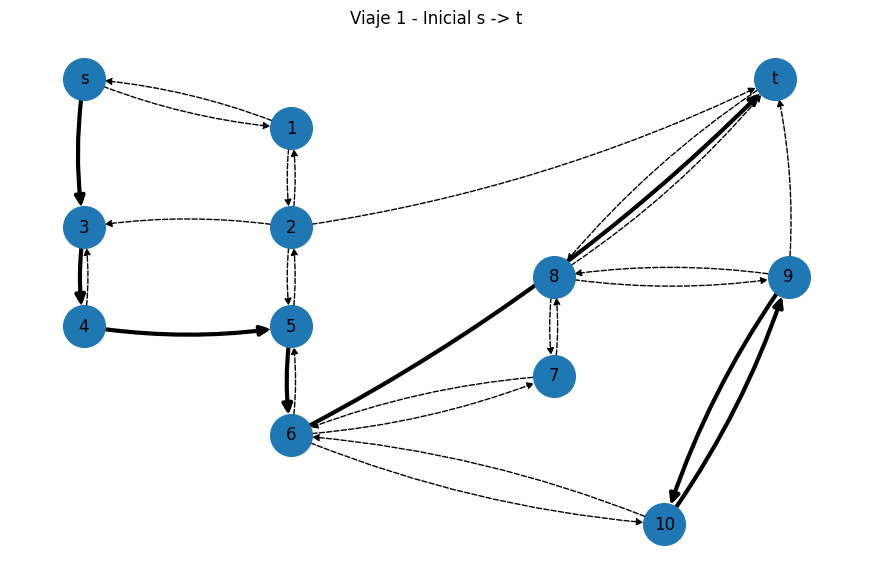

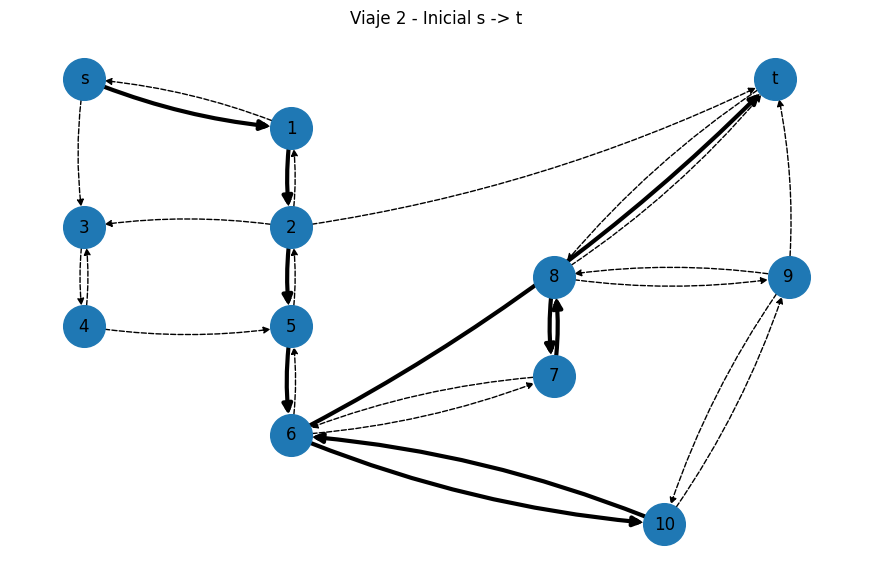

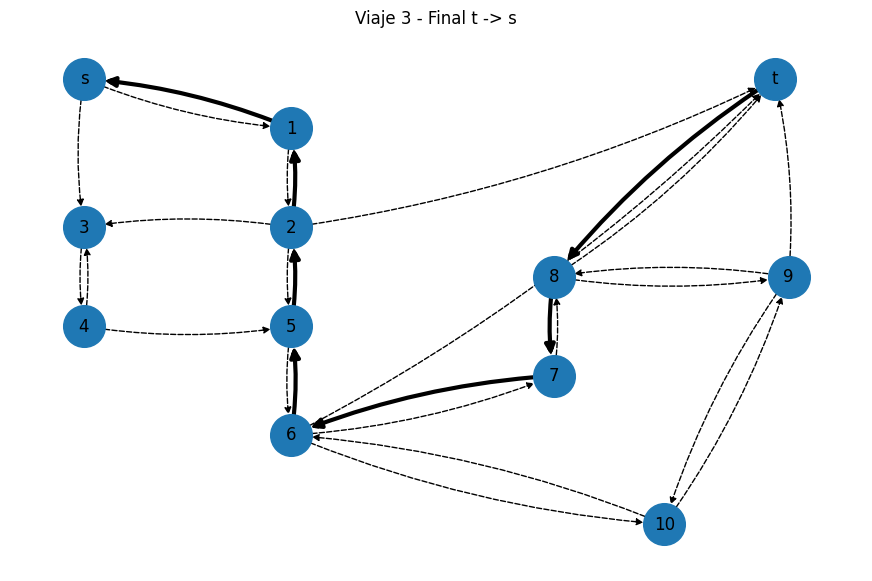

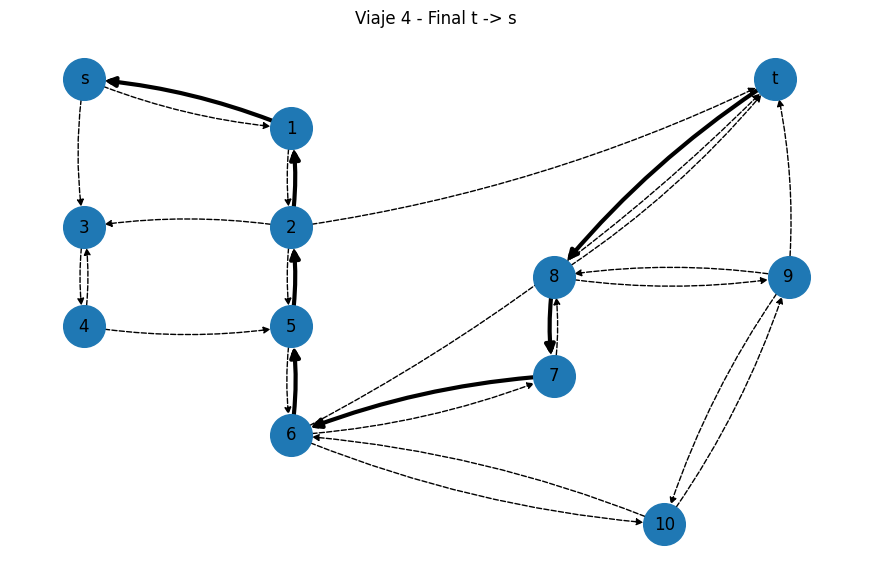

In [57]:
if model.status == GRB.Status.OPTIMAL:

    for r in R:

        arcos_r = []

        for (i,j) in A:

            # Deadheading de este viaje
            veces = int(round(y[r,i,j].X))

            # Servicio: solo existe x en viajes de servicio
            if r in R_servicio and (i,j) in AR and x[r,i,j].X > 0.5:
                veces += 1

            if veces > 0:
                arcos_r.append((i,j))

        plt.figure(figsize=(11,7))

        nx.draw_networkx_nodes(D, pos, node_size=900)
        nx.draw_networkx_labels(D, pos)

        nx.draw_networkx_edges(
            D, pos,
            edgelist=A,
            arrows=True,
            node_size=900,
            arrowsize=10,
            width=1,
            style="dashed",
            connectionstyle="arc3,rad=0.08"
        )

        nx.draw_networkx_edges(
            D, pos,
            edgelist=arcos_r,
            arrows=True,
            node_size=900,
            arrowsize=14,
            width=3,
            connectionstyle="arc3,rad=0.08"
        )

        if r in R_iniciales:
            tipo = "Inicial s -> t"
        elif r in R_finales:
            tipo = "Final t -> s"
        else:
            tipo = "Intermedio t -> t"

        plt.title("Viaje {} - {}".format(r,tipo))
        plt.axis("off")
        plt.show()

In [58]:
from collections import defaultdict

def arcos_usados(r):
    """Arcos (con multiplicidad) recorridos en el viaje r."""
    usados = []
    for (i,j) in A:
        veces = int(round(y[r,i,j].X))
        if r in R_servicio and (i,j) in AR and x[r,i,j].X > 0.5:
            veces += 1
        usados += [(i,j)] * veces
    return usados

def componentes_conexas(arcos):
    """Componentes conexas (ignorando sentido) del grafo de arcos usados."""
    adj = defaultdict(set)
    for (i,j) in arcos:
        adj[i].add(j)
        adj[j].add(i)
    visto, comps = set(), []
    for v in adj:
        if v in visto:
            continue
        comp, pila = set(), [v]
        while pila:
            u = pila.pop()
            if u in comp:
                continue
            comp.add(u)
            pila.extend(adj[u] - comp)
        visto |= comp
        comps.append(comp)
    return comps

def reportar(etiqueta):
    print("=" * 70)
    print(etiqueta)
    print("=" * 70)
    if model.status != GRB.Status.OPTIMAL:
        print("Estado de Gurobi:", model.status)
        return
    print("Objetivo:", round(model.ObjVal, 2))
    for r in R:
        comps = componentes_conexas(arcos_usados(r))
        marca = "OK" if len(comps) == 1 else "<<< DESCONECTADO"
        print(f"  Viaje {r}: {len(comps)} componente(s) {marca}")
        if len(comps) > 1:
            for k, comp in enumerate(comps, 1):
                print(f"      comp {k}: {sorted(comp)}")

def quitar(prefijo):
    cs = [c for c in model.getConstrs() if c.ConstrName.startswith(prefijo)]
    model.remove(cs)
    model.update()
    print(f"Se eliminaron {len(cs)} restricciones '{prefijo}*'")

# 0) Modelo completo (línea base)
reportar("MODELO COMPLETO (C1 + C2 + C3 + C4)")

# 1) Sin C4
quitar("C4_")
model.optimize()
reportar("SIN C4")

# 2) Sin C4 y sin C2
quitar("C2_")
model.optimize()
reportar("SIN C4 Y SIN C2")

MODELO COMPLETO (C1 + C2 + C3 + C4)
Objetivo: 107.0
  Viaje 1: 2 componente(s) <<< DESCONECTADO
      comp 1: ['3', '4', '5', '6', 's', 't']
      comp 2: ['10', '9']
  Viaje 2: 2 componente(s) <<< DESCONECTADO
      comp 1: ['1', '10', '2', '5', '6', 's', 't']
      comp 2: ['7', '8']
  Viaje 3: 1 componente(s) OK
  Viaje 4: 1 componente(s) OK
Se eliminaron 0 restricciones 'C4_*'
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 193 rows, 306 columns and 1116 nonzeros (Min)
Model fingerprint: 0x877262c7
Model has 122 linear objective coefficients
Variable types: 136 continuous, 170 integer (58 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+03]
  Objective range  [2e+00, 6e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+04]

Presolved: 64 rows, 79

# Resumen de todo lo que hicimos

## 1. Cambios al modelo (tarea 0, se pidió reestructurar los viajes finales)

- **Variables $x$**: Antes definidas para todos los viajes $R$. Ahora solo para $R_{\text{servicio}}$ (iniciales + intermedios).
- **Variables $y$**: Todos los viajes (igual, no cambió).
- **`recorrido(r,i,j)`**: Antes siempre usaba $x + y$ en arcos requeridos. Ahora en viajes finales devuelve solo $y$; en los demás, $x + y$ si el arco es requerido.
- **Función objetivo**: Antes $c \cdot x$ sobre todos los $r$. Ahora $c \cdot x$ solo sobre $R_{\text{servicio}}$.
- **Restricciones (2)–(11)**: Sin cambio de código (ya usan `recorrido`).
- **Restricción (RF)**: Antes prohibía servir en finales. Ahora eliminada (daría `KeyError` y ya no hace falta).
- **(13) capacidad y (14) servicio**: Antes sumaban sobre $R$. Ahora suman sobre $R_{\text{servicio}}$.

*El óptimo se mantuvo en 109, igual que con RF, así que la reestructuración es equivalente.*

## 2. Cambios al resumen y a los gráficos

- `informacion_viaje`: protegida para los viajes finales (`servidos = []` si $r$ no está en $R_{\text{servicio}}$).
- Nueva `construir_ruta` (Hierholzer): arma la secuencia de nodos de cada viaje. Reemplaza a `rutas[r]`, que no estaba definida. Empieza en $s$ para los iniciales y en $t$ para los demás.
- Celda de gráficos: una sola condición `if r in R_servicio and (i,j) in AR and x[r,i,j].X > 0.5`, puesta después de calcular `veces`.
- `uso_conexion(r,i,j)`: definida (suma recorrido de ambos sentidos de la conexión), porque C2 la llamaba y no existía.

## 3. Conectividad compacta (C1–C4)

Pruebas hechas y conclusiones:
- **Modelo completo**: Objetivo 109, los 4 viajes conectados (línea base).
- **Sin C4**: Objetivo 109, conectado -> C4 es redundante (suma de las C3).
- **Con $d(10,9)=0$, completo**: Objetivo 109, conectado -> el modelo evita el subtour.
- **Con $d(10,9)=0$, sin C2 ni C4**: Objetivo 107, viajes 1 y 2 desconectados (ciclos `{9,10}` y `{7,8}`) -> C2 es necesaria.

Quedó decidido:
- Se elimina C4.
- Se mantiene C2, con $N_{\text{flujo}} = |V|-1$.
- Se mantienen C1 y C3.

## 4. Cota $M$

Reemplazamos $M_{\text{con}} = 1000$ en C1b por una cota que no depende del número de nodos:
- $$M_{r,v}=2(\bar{k}+1)+\min\{\bar{k},\ \deg_R(v)\},\qquad \bar{k}=\begin{cases}\bar{k}_{\text{cap}} & r\in R_{\text{servicio}}\\ 0 & r\in R_{\text{finales}}\end{cases}$$
- $\bar{k} = 5$, sale de las demandas ordenadas de menor a mayor.
- $M$ queda entre 12 y 14 en viajes de servicio y en 2 en finales.
- El argumento es que existe un óptimo cuyos tramos de deadheading son caminos simples en $G-\{t\}$, con a lo sumo $k+1$ tramos por viaje.
- Verificado: el objetivo sigue en 109. En los viajes finales la cota es exacta (holgura 0).


## reiniciar el kernel para ver toso de nuevo